# SHAP analysis of the Admissio yield forecaster

This notebook explains the registered forecaster on the 2024 hold-out cycle. The model forecasts the change in yield from last cycle, so every SHAP value is a contribution, in percentage points, to that change. Run `python -m src.pipeline.flow` and `python -m src.models.train` first.

In [1]:
import os
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir("..")

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap

from src.explain.run import example_institutions
from src.explain.shap_values import shap_explanation, top_drivers
from src.models.dataset import load_modelling_data

%matplotlib inline
FIGURES = Path("docs/figures")
FIGURES.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"font.family": "DejaVu Sans", "savefig.dpi": 200, "savefig.bbox": "tight"})

data = load_modelling_data()
forecaster = joblib.load("models/admissio_yield.joblib")
explanation = shap_explanation(forecaster, data.test, data.train)
points = shap.Explanation(values=100 * explanation.values, base_values=100 * explanation.base_values,
                          data=explanation.data, feature_names=explanation.feature_names)
print(f"{len(data.test)} institutions explained; expected change {points.base_values[0]:.2f} points")

1852 institutions explained; expected change -0.69 points


In [2]:
reconstructed = explanation.base_values + explanation.values.sum(axis=1)
print("SHAP values add up to the model output:", np.allclose(reconstructed, forecaster.predict_change(data.test), atol=1e-6))

SHAP values add up to the model output: True


## Global importance

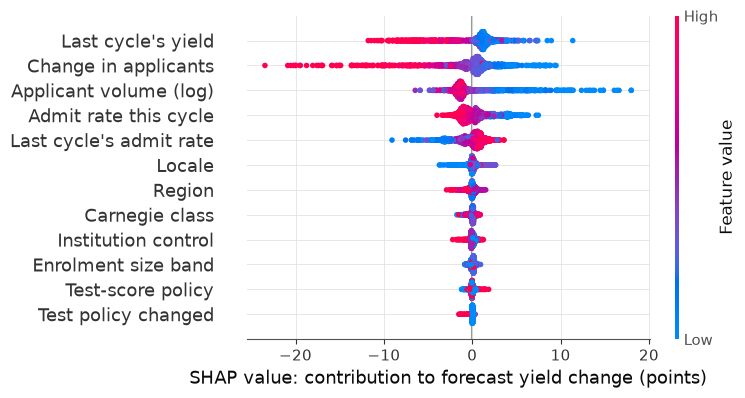

In [3]:
shap.plots.beeswarm(points, max_display=12, show=False, plot_size=(6.5, 4.2))
plt.xlabel("SHAP value: contribution to forecast yield change (points)")
plt.savefig(FIGURES / "shap_summary.png", facecolor="white")
plt.show()

In [4]:
importance = pd.Series(np.abs(points.values).mean(axis=0), index=points.feature_names).sort_values(ascending=False)
importance.round(3).rename("mean |SHAP| (points)").to_frame()

,mean |SHAP| (points)
Last cycle's yield,2.046
Change in applicants,2.028
Applicant volume (log),1.949
Admit rate this cycle,1.208
Last cycle's admit rate,1.056
Locale,0.285
Region,0.251
Carnegie class,0.196
Institution control,0.182
Enrolment size band,0.173


**Reading the global picture.** Five inputs carry almost all of the signal: last cycle's yield, the change in applicants, applicant volume, and the admit rate this cycle and last cycle. Each moves the forecast change by one to two points on average. Institutional descriptors such as locale, region, Carnegie class, control and size band add a few tenths of a point, and the test-score policy barely registers. The model therefore forecasts from an institution's own funnel history rather than from what kind of institution it is, which is the behaviour the Module 2 explainability framework asked for.

## How the two strongest drivers behave

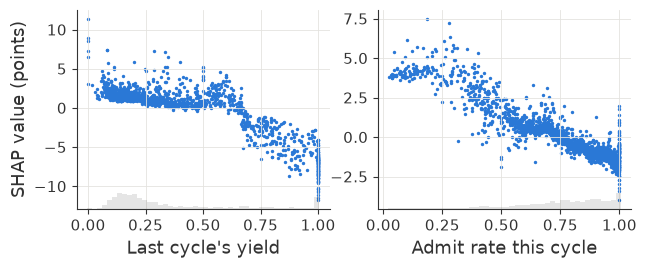

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(6.5, 2.8))
shap.plots.scatter(points[:, "Last cycle's yield"], ax=axes[0], show=False, color="#2a78d6", dot_size=6)
shap.plots.scatter(points[:, "Admit rate this cycle"], ax=axes[1], show=False, color="#2a78d6", dot_size=6)
axes[0].set_ylabel("SHAP value (points)")
axes[1].set_ylabel("")
fig.tight_layout()
fig.savefig(FIGURES / "shap_dependence.png", facecolor="white")
plt.show()

**Two business patterns.** Institutions whose yield was above roughly 60% last cycle are pulled down by about four points, a regression-to-the-mean effect that a naive carry-forward forecast cannot capture. Admit rate works in the opposite direction: when an institution admits fewer than about 56% of applicants the forecast change rises by close to three points, and when it admits more than about 93% it falls by about one point. Offering places more widely reaches applicants who are less committed, so yield drops. These are associations in historical data, not causal effects of changing offer volume.

## Do the drivers differ by fairness group?

In [6]:
by_group = pd.DataFrame(np.abs(points.values), columns=points.feature_names).groupby(data.test_groups.to_numpy()).mean()
by_group.T.round(2)

,All other institutions,HBCU,Private for-profit,"Under 1,000 students"
Last cycle's yield,1.26,1.50,4.08,3.44
Admit rate this cycle,1.16,1.17,1.39,1.28
Last cycle's admit rate,0.94,0.99,1.28,1.28
Change in applicants,1.39,2.19,3.96,3.04
Applicant volume (log),1.43,1.41,3.51,2.83
Test policy changed,0.03,0.04,0.08,0.09
Test-score policy,0.10,0.08,0.26,0.20
Institution control,0.13,0.15,0.60,0.19
Enrolment size band,0.18,0.20,0.18,0.14
Locale,0.17,0.23,0.65,0.47


**Group differences.** For private for-profit institutions and institutions under 1,000 students, the average absolute SHAP value of the history features is two to three times larger than for other institutions. The model is not relying on group membership itself, since the control and size-band features stay small for every group. Instead, the funnel histories of small institutions swing more from cycle to cycle, so the same features push their forecasts further. That volatility is the main reason their forecast errors remain larger.

## Local explanations

In [7]:
examples = example_institutions(data)
for label, row in examples.items():
    position = data.test.index.get_loc(row.index[0])
    print(label, "|", row["INSTNM"].iloc[0], "| last yield", round(100 * row["YIELD_LAG1"].iloc[0], 1),
          "| forecast", round(100 * forecaster.predict(row)[0], 1), "| actual", round(100 * row["YIELD"].iloc[0], 1))
    print("   top drivers:", top_drivers(explanation, position))

HBCU | Morgan State University | last yield 12.1 | forecast 11.3 | actual 12.4
   top drivers: [{'feature': 'Applicant volume (log)', 'value': 10.059080049588058, 'contribution_points': -1.33}, {'feature': "Last cycle's yield", 'value': 0.12096474953617811, 'contribution_points': 1.11}, {'feature': 'Change in applicants', 'value': 0.027483400026384063, 'contribution_points': 0.48}]
Small for-profit | St Louis College of Health Careers-Fenton | last yield 77.8 | forecast 73.5 | actual 60.7
   top drivers: [{'feature': 'Change in applicants', 'value': 1.5925925925925926, 'contribution_points': -8.35}, {'feature': 'Applicant volume (log)', 'value': 4.2626798770413155, 'contribution_points': 5.24}, {'feature': "Last cycle's yield", 'value': 0.7777777777777778, 'contribution_points': -3.72}]
Large public | University of Illinois Chicago | last yield 23.3 | forecast 23.2 | actual 21.1
   top drivers: [{'feature': 'Applicant volume (log)', 'value': 10.206772268215317, 'contribution_points': -

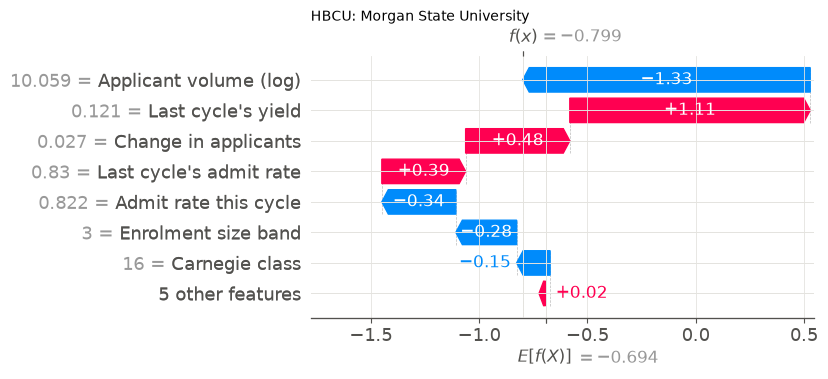

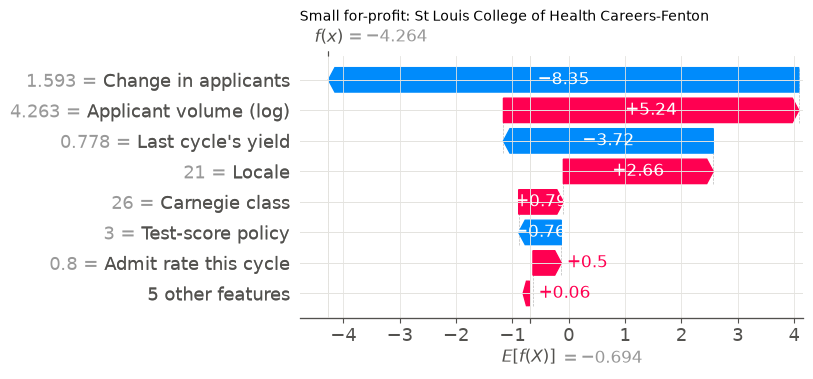

In [8]:
for label, filename in [("HBCU", "shap_waterfall_hbcu.png"), ("Small for-profit", "shap_waterfall_small_for_profit.png")]:
    position = data.test.index.get_loc(examples[label].index[0])
    plt.close("all")
    plt.figure(figsize=(6.5, 3.4))
    shap.plots.waterfall(points[position], max_display=8, show=False)
    plt.gcf().set_size_inches(6.5, 3.4)
    plt.title(f"{label}: {examples[label]['INSTNM'].iloc[0]}", loc="left", fontsize=10)
    plt.savefig(FIGURES / filename, facecolor="white")
    plt.show()

**Local explanations.** For Morgan State University, its large applicant volume lowers the forecast change by 1.3 points and slightly outweighs the 1.1-point lift from its low last-cycle yield, so the forecast sits just below last cycle's figure. The actual 2024 yield landed within half a point of last cycle's value. For the small for-profit college, applicants rose by 159%, which pulls the forecast down by 8.4 points, and its small applicant pool offsets part of that pull. Its actual yield fell further than forecast, which illustrates why intervals for small institutions are much wider.